# Low-data fine-tuning: linear probe vs partial FT vs full FT vs LoRA

ML4CV project work (Prof. S. Salti).

**Question.** How does the best adaptation strategy of a pre-trained backbone change with the amount of labelled data?

**Hypotheses (written before running any experiment).**
1. With 1-5 examples per class, linear probe and LoRA are at least as good as full fine-tuning (which overfits).
2. With more data full fine-tuning catches up and eventually wins: there is a crossover point.
3. CLIP features are better than supervised ImageNet features in the low-shot regime.

**Protocol.** Fixed hyperparameters per method (no tuning on the test set), 3 seeds (0, 1, 2) for every configuration, mean and std reported. Seeds are fixed by the course requirements; variants can be cut instead.

**Variants cut order if time is short:** second backbone, `partial_ft` k, shots, LoRA rank.

In [7]:
import itertools, math, random, time
from pathlib import Path
import numpy as np
import pandas as pd
import timm
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import ConcatDataset, DataLoader, Subset
import torchvision
from torchvision import transforms as T

SEEDS = [0, 1, 2]
DATASETS = ['flowers102', 'pets']
BACKBONES = ['clip_vitb16', 'vit_b16_sup']
METHODS = ['linear_probe', 'partial_ft', 'full_ft', 'lora']
SHOTS = [1, 5, 'full']
PARTIAL_K = 4
LORA_RANK = 8
DATA_ROOT = Path('data')
RESULTS_CSV = Path('results/results.csv')
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

# Hyperparameters: fixed a priori from common defaults, identical for every dataset/backbone/shot, never tuned on the test set.
TIMM_NAME = {
    'clip_vitb16': 'vit_base_patch16_clip_224.openai',      # OpenAI CLIP image tower (no projection / text tower)
    'vit_b16_sup': 'vit_base_patch16_224.augreg_in1k',      # supervised, ImageNet-1k only
}
BATCH_SIZE = 32
EPOCHS = 10          # passes over the training subset ...
MIN_STEPS = 100      # ... but never fewer optimizer steps than this (1-shot subsets are tiny)
WEIGHT_DECAY = 0.01
HEAD_LR = 1e-3
BODY_LR = {'partial_ft': 1e-5, 'full_ft': 1e-5, 'lora': 5e-4}
LORA_ALPHA = 16
WARMUP_FRAC = 0.1
NUM_WORKERS = 8

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


## Data

Flowers102 uses train+val as training pool (20 images/class) and the official test split. Pets uses `trainval` and `test`. K-shot subsets are sampled per seed from the training pool.

In [ ]:
NORM = {
    'clip_vitb16': ((0.4815, 0.4578, 0.4082), (0.2686, 0.2613, 0.2758)),
    'vit_b16_sup': ((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
}

def get_transform(backbone, train):
    mean, std = NORM[backbone]
    if train:
        aug = [T.RandomResizedCrop(224, scale=(0.5, 1.0)), T.RandomHorizontalFlip()]
    else:
        aug = [T.Resize(256), T.CenterCrop(224)]
    return T.Compose(aug + [T.ToTensor(), T.Normalize(mean, std)])

def load_dataset(name, backbone, test_tf=None, train_tf=None):
    tf_train, tf_test = train_tf or get_transform(backbone, True), test_tf or get_transform(backbone, False)
    root = DATA_ROOT / name
    if name == 'flowers102':
        mk = lambda split, tf: torchvision.datasets.Flowers102(root, split=split, transform=tf, download=True)
        train = ConcatDataset([mk('train', tf_train), mk('val', tf_train)])
        labels = list(mk('train', None)._labels) + list(mk('val', None)._labels)  # _labels is private in torchvision
        test = mk('test', tf_test)
    elif name == 'pets':
        train = torchvision.datasets.OxfordIIITPet(root, split='trainval', transform=tf_train, download=True)
        labels = list(train._labels)
        test = torchvision.datasets.OxfordIIITPet(root, split='test', transform=tf_test, download=True)
    else:
        raise ValueError(name)
    return train, labels, test

def few_shot_indices(labels, shots, seed):
    if shots == 'full':
        return list(range(len(labels)))
    rng = np.random.default_rng(seed)
    labels = np.asarray(labels)
    idx = [rng.choice(np.flatnonzero(labels == c), shots, replace=False) for c in np.unique(labels)]
    return np.concatenate(idx).tolist()

_TEST_CACHE = {}

def cached_test_set(name):
    """Test preprocessing is deterministic: decode once as uint8; normalisation is applied on the GPU per backbone."""
    if name not in _TEST_CACHE:
        test = load_dataset(name, 'vit_b16_sup', T.Compose([T.Resize(256), T.CenterCrop(224), T.PILToTensor()]))[2]
        xs, ys = zip(*DataLoader(test, batch_size=128, num_workers=NUM_WORKERS))
        assert xs[0].dtype == torch.uint8
        _TEST_CACHE[name] = (torch.cat(xs), torch.cat(ys))
    return _TEST_CACHE[name]


## Models and methods

| method | trainable parameters |
|---|---|
| `linear_probe` | linear head on frozen features |
| `partial_ft` | head + last `PARTIAL_K` transformer blocks + final norm |
| `full_ft` | everything |
| `lora` | head + LoRA adapters (rank `LORA_RANK`, scale `LORA_ALPHA / LORA_RANK`) on `qkv` and `proj` of every block |

Backbones come from `timm`: `vit_base_patch16_clip_224.openai` (CLIP image tower only, no projection, no text tower) and `vit_base_patch16_224.augreg_in1k` (supervised, ImageNet-1k only). The head is a new linear layer initialised at zero.

**Training protocol (identical for all datasets, backbones and shot counts).** AdamW, weight decay 0.01, batch 32 (smaller if the subset is smaller), bf16 autocast, linear warm-up (10%) + cosine decay, no early stopping and no validation set. Budget: 10 epochs over the training subset, at least 100 steps. Learning rates: head 1e-3; backbone 1e-5 for `partial_ft` / `full_ft`, 5e-4 for LoRA parameters. The values are common defaults chosen before any run; they are not tuned, so a method may be under- or over-tuned for a given regime (see limitations). The k-shot subset of a given seed is the same for every method and backbone (paired comparison).


In [9]:
class LoRALinear(nn.Module):
    def __init__(self, base, rank, alpha):
        super().__init__()
        self.base = base
        self.A = nn.Parameter(torch.empty(rank, base.in_features))
        self.B = nn.Parameter(torch.zeros(base.out_features, rank))  # zero init: starts equal to the pre-trained model
        nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
        self.scale = alpha / rank

    def forward(self, x):
        return self.base(x) + (x @ self.A.T @ self.B.T) * self.scale

def build_model(backbone, method, num_classes):
    model = timm.create_model(TIMM_NAME[backbone], pretrained=True, num_classes=num_classes)
    nn.init.zeros_(model.head.weight)
    nn.init.zeros_(model.head.bias)
    for p in model.parameters():
        p.requires_grad = method == 'full_ft'
    if method == 'partial_ft':
        for mod in [*model.blocks[-PARTIAL_K:], model.norm]:
            for p in mod.parameters():
                p.requires_grad = True
    elif method == 'lora':
        for blk in model.blocks:
            blk.attn.qkv = LoRALinear(blk.attn.qkv, LORA_RANK, LORA_ALPHA)
            blk.attn.proj = LoRALinear(blk.attn.proj, LORA_RANK, LORA_ALPHA)
    for p in model.head.parameters():
        p.requires_grad = True
    return model

def make_optimizer(model, method):
    head = list(model.head.parameters())
    head_ids = {id(p) for p in head}
    body = [p for p in model.parameters() if p.requires_grad and id(p) not in head_ids]
    groups = [dict(params=head, lr=HEAD_LR)]
    if body:
        groups.append(dict(params=body, lr=BODY_LR[method]))
    return torch.optim.AdamW(groups, weight_decay=WEIGHT_DECAY)

@torch.no_grad()
def evaluate(model, backbone, x_u8, y, bs=128):
    model.eval()
    mean, std = (torch.tensor(v, device=DEVICE).view(1, 3, 1, 1) for v in NORM[backbone])
    correct = 0
    for i in range(0, len(y), bs):
        x = (x_u8[i:i + bs].to(DEVICE).float() / 255 - mean) / std
        with torch.autocast(DEVICE, dtype=torch.bfloat16):
            correct += (model(x).argmax(1).cpu() == y[i:i + bs]).sum().item()
    return correct / len(y)

def train(model, loader, method):
    steps = max(MIN_STEPS, EPOCHS * len(loader))
    warmup = max(1, int(WARMUP_FRAC * steps))
    opt = make_optimizer(model, method)
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / warmup if s < warmup else 0.5 * (1 + math.cos(math.pi * (s - warmup) / (steps - warmup))))
    model.train()
    step = 0
    while step < steps:
        for x, y in loader:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            with torch.autocast(DEVICE, dtype=torch.bfloat16):
                loss = F.cross_entropy(model(x).float(), y)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            sched.step()
            step += 1
            if step == steps:
                break
    return loss.item()

def run_one(dataset, backbone, method, shots, seed):
    set_seed(seed)
    train_ds, labels, _ = load_dataset(dataset, backbone)
    idx = few_shot_indices(labels, shots, seed)
    model = build_model(backbone, method, len(set(labels))).to(DEVICE)
    loader = DataLoader(Subset(train_ds, idx), batch_size=min(BATCH_SIZE, len(idx)), shuffle=True,
                        num_workers=NUM_WORKERS, pin_memory=True)
    train(model, loader, method)
    return evaluate(model, backbone, *cached_test_set(dataset))


## Experiments

The loop appends to `results/results.csv` and skips configurations already done, so it can be interrupted and resumed.

In [10]:
RESULTS_CSV.parent.mkdir(exist_ok=True)

def done_keys():
    if not RESULTS_CSV.exists():
        return set()
    df = pd.read_csv(RESULTS_CSV)
    return set(zip(df.dataset, df.backbone, df.method, df.shots.astype(str), df.seed))

done = done_keys()
for ds, bb, m, k, s in itertools.product(DATASETS, BACKBONES, METHODS, SHOTS, SEEDS):
    if (ds, bb, m, str(k), s) in done:
        continue
    t0 = time.time()
    test_acc = run_one(ds, bb, m, k, s)
    row = dict(dataset=ds, backbone=bb, method=m, shots=k, seed=s, test_acc=test_acc, time_s=time.time() - t0)
    pd.DataFrame([row]).to_csv(RESULTS_CSV, mode='a', header=not RESULTS_CSV.exists(), index=False)

## Results

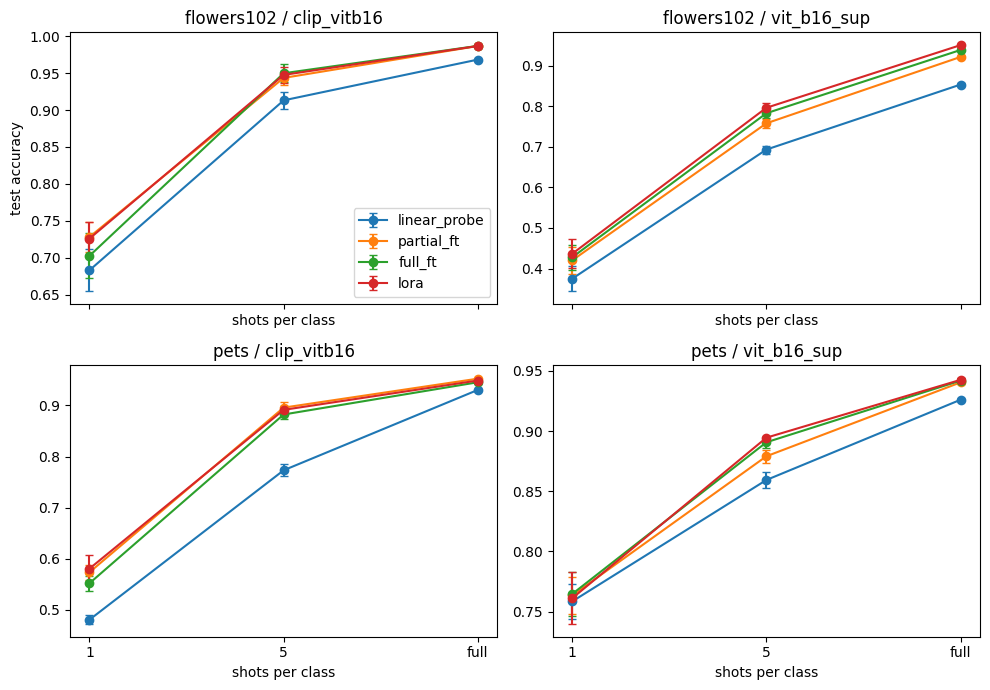

mean     std
dataset    backbone    method       shots                
flowers102 clip_vitb16 full_ft      1      0.7028  0.0305
                                    5      0.9497  0.0123
                                    full   0.9867  0.0009
                       linear_probe 1      0.6833  0.0284
                                    5      0.9130  0.0117
                                    full   0.9682  0.0012
                       lora         1      0.7261  0.0222
                                    5      0.9475  0.0105
                                    full   0.9866  0.0018
                       partial_ft   1      0.7282  0.0199
                                    5      0.9434  0.0099
                                    full   0.9866  0.0007
           vit_b16_sup full_ft      1      0.4277  0.0312
                                    5      0.7828  0.0123
                                    full   0.9386  0.0006
                       linear_probe 1      0.3749  0.0310
                                    5      0.6932  0.0100
                                    full   0.8535  0.0027
                       lora         1      0.4364  0.0356
                                    5      0.7962  0.0126
                                    full   0.9506  0.0011
                       partial_ft   1      0.4202  0.0337
                                    5      0.7580  0.0114
                                    full   0.9215  0.0014
pets       clip_vitb16 full_ft      1      0.5519  0.0150
                                    5      0.8823  0.0087
                                    full   0.9455  0.0035
                       linear_probe 1      0.4806  0.0091
                                    5      0.7731  0.0120
                                    full   0.9305  0.0012
                       lora         1      0.5805  0.0275
                                    5      0.8914  0.0083
                                    full   0.9489  0.0019
                       partial_ft   1      0.5735  0.0146
                                    5      0.8958  0.0111
                                    full   0.9525  0.0018
           vit_b16_sup full_ft      1      0.7646  0.0185
                                    5      0.8907  0.0046
                                    full   0.9419  0.0017
                       linear_probe 1      0.7584  0.0144
                                    5      0.8594  0.0070
                                    full   0.9260  0.0006
                       lora         1      0.7611  0.0217
                                    5      0.8945  0.0007
                                    full   0.9426  0.0018
                       partial_ft   1      0.7634  0.0153
                                    5      0.8791  0.0055
                                    full   0.9405  0.0015

In [11]:
import matplotlib.pyplot as plt

df = pd.read_csv(RESULTS_CSV).assign(shots=lambda d: d.shots.astype(str))
shot_labels = [str(k) for k in SHOTS]
summary = df.groupby(['dataset', 'backbone', 'method', 'shots']).test_acc.agg(['mean', 'std']).round(4)

fig, axes = plt.subplots(len(DATASETS), len(BACKBONES), figsize=(10, 7), sharex=True, squeeze=False)
for i, ds in enumerate(DATASETS):
    for j, bb in enumerate(BACKBONES):
        ax = axes[i, j]
        for m in METHODS:
            g = df[(df.dataset == ds) & (df.backbone == bb) & (df.method == m)].groupby('shots').test_acc.agg(['mean', 'std']).reindex(shot_labels)
            ax.errorbar(range(len(g)), g['mean'], g['std'], marker='o', capsize=3, label=m)
        ax.set(xticks=range(len(shot_labels)), xticklabels=shot_labels, title=f'{ds} / {bb}')
        ax.set_xlabel('shots per class')
axes[0, 0].set_ylabel('test accuracy')
axes[0, 0].legend()
plt.tight_layout()
plt.show()
summary


In [12]:
# Paired differences (same seed => same k-shot subset). H1/H2: full_ft vs the cheaper methods; H3: CLIP vs supervised.
# String order '1' < '5' < 'full' matches the shot order.
acc = df.pivot_table(index=['dataset', 'backbone', 'shots', 'seed'], columns='method', values='test_acc')
paired = pd.DataFrame({'full_ft - linear_probe': acc.full_ft - acc.linear_probe, 'full_ft - lora': acc.full_ft - acc.lora})
display(paired.groupby(['dataset', 'backbone', 'shots']).agg(['mean', 'std']).round(3))

by_bb = df.pivot_table(index=['dataset', 'method', 'shots', 'seed'], columns='backbone', values='test_acc')
clip_gain = (by_bb.clip_vitb16 - by_bb.vit_b16_sup).rename('clip - sup')
clip_gain.groupby(['dataset', 'method', 'shots']).agg(['mean', 'std']).round(3)


full_ft - linear_probe        full_ft - lora  \
                                               mean    std           mean   
dataset    backbone    shots                                                
flowers102 clip_vitb16 1                      0.020  0.014         -0.023   
                       5                      0.037  0.001          0.002   
                       full                   0.019  0.002          0.000   
           vit_b16_sup 1                      0.053  0.008         -0.009   
                       5                      0.090  0.009         -0.013   
                       full                   0.085  0.003         -0.012   
pets       clip_vitb16 1                      0.071  0.011         -0.029   
                       5                      0.109  0.017         -0.009   
                       full                   0.015  0.004         -0.003   
           vit_b16_sup 1                      0.006  0.004          0.004   
                       5                      0.031  0.003         -0.004   
                       full                   0.016  0.002         -0.001   

                                     
                                std  
dataset    backbone    shots         
flowers102 clip_vitb16 1      0.020  
                       5      0.003  
                       full   0.002  
           vit_b16_sup 1      0.006  
                       5      0.005  
                       full   0.001  
pets       clip_vitb16 1      0.013  
                       5      0.001  
                       full   0.005  
           vit_b16_sup 1      0.006  
                       5      0.005  
                       full   0.003

mean    std
dataset    method       shots              
flowers102 full_ft      1      0.275  0.011
                        5      0.167  0.007
                        full   0.048  0.001
           linear_probe 1      0.308  0.005
                        5      0.220  0.003
                        full   0.115  0.003
           lora         1      0.290  0.018
                        5      0.151  0.002
                        full   0.036  0.002
           partial_ft   1      0.308  0.015
                        5      0.185  0.002
                        full   0.065  0.001
pets       full_ft      1     -0.213  0.026
                        5     -0.008  0.010
                        full   0.004  0.005
           linear_probe 1     -0.278  0.023
                        5     -0.086  0.018
                        full   0.004  0.002
           lora         1     -0.181  0.042
                        5     -0.003  0.008
                        full   0.006  0.004
           partial_ft   1     -0.190  0.018
                        5      0.017  0.016
                        full   0.012  0.003

## Ablations

Scope: Flowers102, CLIP ViT-B/16, 1 and 5 shots, 3 seeds (same k-shot subsets as the main study). One factor is changed at a time; the reference value is the main-study run (LoRA rank 8, `PARTIAL_K` 4, linear probe 100+ steps with head lr 1e-3).

1. **LoRA rank** in {1, 2, 4, 8, 16}.
2. **Number of unfrozen blocks** `PARTIAL_K` in {1, 2, 4, 8, 12}; 12 = all transformer blocks, which differs from `full_ft` only in the patch embedding and positional embeddings.
3. **Linear-probe budget** (sensitivity check for H1): 500 steps, or head lr 1e-2 instead of 1e-3.

These runs are a sensitivity analysis on the test set: they do not replace the fixed hyperparameters of the main study, and no value is selected from them.


In [13]:
ABLATION_CSV = Path('results/ablation.csv')
ABL_DATASET, ABL_BACKBONE, ABL_SHOTS = 'flowers102', 'clip_vitb16', [1, 5]
# (study, method, global to override, values to run)
ABLATIONS = [
    ('lora_rank', 'lora', 'LORA_RANK', [1, 2, 4, 16]),
    ('partial_k', 'partial_ft', 'PARTIAL_K', [1, 2, 8, 12]),
    ('lp_min_steps', 'linear_probe', 'MIN_STEPS', [500]),
    ('lp_head_lr', 'linear_probe', 'HEAD_LR', [1e-2]),
]

def run_ablation(method, var, value, shots, seed):
    default = globals()[var]
    globals()[var] = value
    try:
        return run_one(ABL_DATASET, ABL_BACKBONE, method, shots, seed)
    finally:
        globals()[var] = default

def abl_done():
    if not ABLATION_CSV.exists():
        return set()
    d = pd.read_csv(ABLATION_CSV)
    return set(zip(d.study, d.value.astype(float), d.shots, d.seed))

done_abl = abl_done()
for (study, method, var, values), value, k, s in ((a, v, k, s) for a in ABLATIONS for v in a[3] for k in ABL_SHOTS for s in SEEDS):
    if (study, float(value), k, s) in done_abl:
        continue
    t0 = time.time()
    acc_ = run_ablation(method, var, value, k, s)
    row = dict(study=study, method=method, value=value, shots=k, seed=s, test_acc=acc_, time_s=time.time() - t0)
    pd.DataFrame([row]).to_csv(ABLATION_CSV, mode='a', header=not ABLATION_CSV.exists(), index=False)


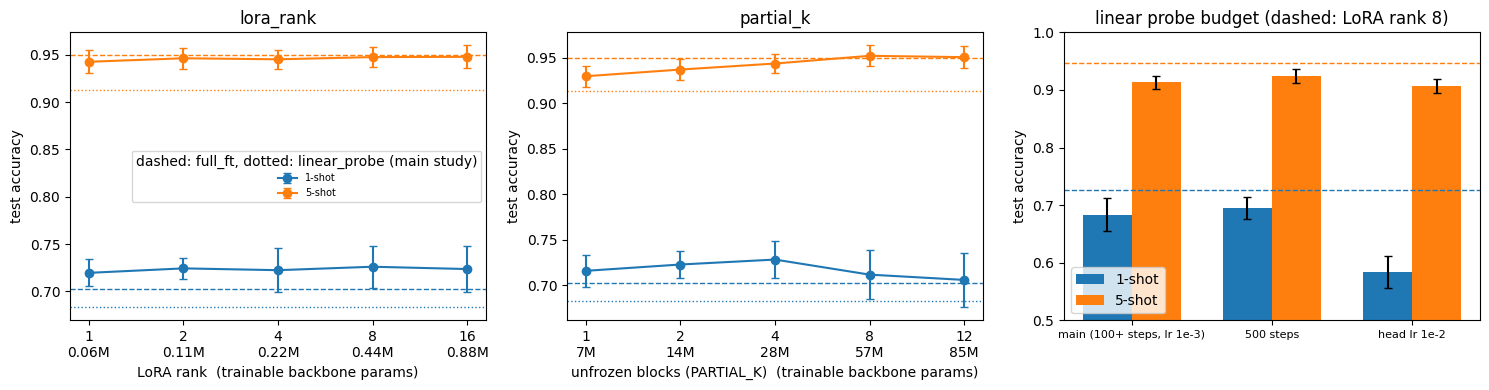

acc  acc_std  delta  delta_std
study        value   shots                                  
lora_rank    1.000   1      0.720    0.014 -0.006      0.010
                     5      0.943    0.012 -0.005      0.003
             2.000   1      0.724    0.011 -0.002      0.012
                     5      0.946    0.011 -0.001      0.002
             4.000   1      0.722    0.024 -0.004      0.008
                     5      0.945    0.010 -0.002      0.000
             8.000   1      0.726    0.022  0.000      0.000
                     5      0.947    0.011  0.000      0.000
             16.000  1      0.724    0.024 -0.002      0.008
                     5      0.948    0.012  0.000      0.002
lp_head_lr   0.001   1      0.683    0.028  0.000      0.000
                     5      0.913    0.012  0.000      0.000
             0.010   1      0.584    0.028 -0.099      0.005
                     5      0.906    0.012 -0.007      0.004
lp_min_steps 100.000 1      0.683    0.028  0.000      0.000
                     5      0.913    0.012  0.000      0.000
             500.000 1      0.695    0.019  0.012      0.010
                     5      0.924    0.012  0.011      0.002
partial_k    1.000   1      0.716    0.018 -0.012      0.003
                     5      0.929    0.012 -0.014      0.002
             2.000   1      0.723    0.015 -0.005      0.005
                     5      0.937    0.012 -0.007      0.002
             4.000   1      0.728    0.020  0.000      0.000
                     5      0.943    0.010  0.000      0.000
             8.000   1      0.712    0.027 -0.017      0.019
                     5      0.952    0.011  0.008      0.003
             12.000  1      0.706    0.030 -0.022      0.020
                     5      0.950    0.012  0.007      0.003

In [14]:
abl = pd.read_csv(ABLATION_CSV).drop(columns='time_s')
base = df[(df.dataset == ABL_DATASET) & (df.backbone == ABL_BACKBONE) & df.shots.isin([str(k) for k in ABL_SHOTS])]
REF = {'lora_rank': ('lora', LORA_RANK), 'partial_k': ('partial_ft', PARTIAL_K),
       'lp_min_steps': ('linear_probe', MIN_STEPS), 'lp_head_lr': ('linear_probe', HEAD_LR)}
ref_rows = [pd.DataFrame(dict(study=st, method=m, value=float(v), shots=base[base.method == m].shots.astype(int),
                              seed=base[base.method == m].seed, test_acc=base[base.method == m].test_acc))
            for st, (m, v) in REF.items()]
abl_all = pd.concat([abl] + ref_rows, ignore_index=True)
abl_all['value'] = abl_all.value.astype(float)

# paired difference w.r.t. the main-study value of the same study, seed and shot count
ref_acc = abl_all[abl_all.value == abl_all.study.map({s: float(v) for s, (m, v) in REF.items()})]
abl_all = abl_all.merge(ref_acc.rename(columns={'test_acc': 'ref_acc'})[['study', 'shots', 'seed', 'ref_acc']], on=['study', 'shots', 'seed'])
abl_all['delta'] = abl_all.test_acc - abl_all.ref_acc
tab = abl_all.groupby(['study', 'value', 'shots']).agg(acc=('test_acc', 'mean'), acc_std=('test_acc', 'std'),
                                                       delta=('delta', 'mean'), delta_std=('delta', 'std')).round(3)

main_mean = lambda m, k: base[(base.method == m) & (base.shots == str(k))].test_acc.mean()
colors = {1: 'tab:blue', 5: 'tab:orange'}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, study, xlabel in zip(axes[:2], ['lora_rank', 'partial_k'], ['LoRA rank', 'unfrozen blocks (PARTIAL_K)']):
    for k in ABL_SHOTS:
        g = abl_all[(abl_all.study == study) & (abl_all.shots == k)].groupby('value').test_acc.agg(['mean', 'std'])
        ax.errorbar(range(len(g)), g['mean'], g['std'], marker='o', capsize=3, color=colors[k], label=f'{k}-shot')
        ax.axhline(main_mean('full_ft', k), color=colors[k], ls='--', lw=1)
        ax.axhline(main_mean('linear_probe', k), color=colors[k], ls=':', lw=1)
    ticks = g.index.astype(int)
    ax.set_xticks(range(len(g)), [f'{v}\n{55296 * v / 1e6:.2f}M' if study == 'lora_rank' else f'{v}\n{7.08 * v:.0f}M' for v in ticks])
    ax.set(xlabel=xlabel + '  (trainable backbone params)', ylabel='test accuracy', title=study)
axes[0].legend(title='dashed: full_ft, dotted: linear_probe (main study)', fontsize=7)

lp = abl_all[abl_all.study.isin(['lp_min_steps', 'lp_head_lr'])]
variants = [('main (100+ steps, lr 1e-3)', None), ('500 steps', ('lp_min_steps', float(MIN_STEPS) * 5)), ('head lr 1e-2', ('lp_head_lr', 1e-2))]
w = 0.35
for i, k in enumerate(ABL_SHOTS):
    vals = [base[(base.method == 'linear_probe') & (base.shots == str(k))].test_acc if v is None
            else lp[(lp.study == v[0]) & (lp.value == v[1]) & (lp.shots == k)].test_acc for _, v in variants]
    axes[2].bar(np.arange(len(vals)) + (i - 0.5) * w, [x.mean() for x in vals], w, yerr=[x.std() for x in vals], capsize=3,
                color=colors[k], label=f'{k}-shot')
    axes[2].axhline(main_mean('lora', k), color=colors[k], ls='--', lw=1)
axes[2].set_xticks(range(len(variants)), [n for n, _ in variants], fontsize=8)
axes[2].set(ylabel='test accuracy', title='linear probe budget (dashed: LoRA rank 8)', ylim=(0.5, 1))
axes[2].legend()
plt.tight_layout()
plt.show()
tab


### Ablation findings

Flowers102, CLIP ViT-B/16, 3 seeds; differences are paired by seed with the main-study value.

- **LoRA rank is not a sensitive factor.** Accuracy is flat from rank 1 to 16 (1 shot: 0.720-0.726; 5 shots: 0.943-0.948), every change is at most 0.006 and within noise. Rank 1 (about 55k trainable backbone parameters) is as good as rank 8, which supports the low intrinsic-rank hypothesis of LoRA in this regime; the fixed rank of 8 in the main study was not a limiting choice.
- **Unfreezing more blocks helps only with more data.** With 5 shots accuracy rises with the number of unfrozen blocks (k=1: 0.929, k=2: 0.937, k=4: 0.943, k=8: 0.952, k=12: 0.950; k=12 matches the main-study `full_ft`, 0.950). With 1 shot the best value is k=4 (0.728) and k=8/12 lose 0.017-0.022, which is about one standard deviation, so it is suggestive and not established.
- **The linear probe is mildly under-trained at the base budget, not badly.** 500 steps give about +0.01 at both shot counts; head lr 1e-2 is worse at 1 shot (-0.10) and about equal at 5 shots (-0.007). Even with 500 steps the probe stays below LoRA (1 shot: 0.695 vs 0.726; 5 shots: 0.924 vs 0.947).
- These runs are a sensitivity analysis on the test set. The main-study hyperparameters were not changed after seeing them.


## Replication of the CLIP-LoRA protocol

The main study differs from CLIP-LoRA (Zanella & Ben Ayed, 2024) on purpose (image tower only, zero-initialised linear head, small budget). To check that the pipeline is not the cause of the gap at 1-4 shots, this section re-implements their protocol as closely as the public description allows and compares with their Table 3 (CLIP ViT-B/16, Flowers102 and Pets):

- CLIP ViT-B/16 (OpenAI weights, `transformers`), both image and text towers adapted; the classifier is the text embedding of "a photo of a [class]." (initialised from zero-shot, logits scaled by the learned CLIP temperature).
- LoRA on the query, key and value projections of every attention block of both towers, rank 2, scaling alpha/r = 1/2, dropout 0.25 on the LoRA input, B initialised at zero.
- AdamW (lr 2e-4, weight decay 0.01), cosine schedule, batch 32, 500 x shots/class iterations, no validation set, last iterate evaluated.
- Training augmentation `RandomResizedCrop(224, scale=(0.08, 1))` + horizontal flip; test: resize 224 (bicubic) + center crop.
- Same few-shot subsets as the main study (seeds 0, 1, 2), shots 1 and 4. 16 shots (8000 steps per run) were not run.
- Known differences: official Flowers102 test split (6,149 images) instead of the CoOp split (2,463); class names from the OpenAI/CLIP-benchmark list; some implementation details (initialisation of dropout, bf16 autocast) are our choice. Zero-shot accuracy is evaluated as a sanity check of the pipeline (paper: Flowers 71.4, Pets 89.1).


In [ ]:
import json
from transformers import CLIPModel, CLIPTokenizer

REPLICATION_CSV = Path('results/replication.csv')
HF_CLIP = 'openai/clip-vit-base-patch16'
_names = json.load(open(DATA_ROOT / 'en_classnames.json'))  # CLIP-benchmark list, same order as the torchvision labels
CLASSNAMES = {'flowers102': _names['flowers'], 'pets': _names['pets']}
REP = dict(rank=2, alpha=1, dropout=0.25, lr=2e-4, wd=0.01, bs=32, iters_per_shot=500)
REP_SHOTS = [1, 4]
BICUBIC = T.InterpolationMode.BICUBIC
REP_TRAIN_TF = T.Compose([T.RandomResizedCrop(224, scale=(0.08, 1.0), interpolation=BICUBIC), T.RandomHorizontalFlip(),
                          T.ToTensor(), T.Normalize(*NORM['clip_vitb16'])])
REP_TEST_TF = T.Compose([T.Resize(224, interpolation=BICUBIC), T.CenterCrop(224), T.PILToTensor()])
_REP_TEST = {}

class LoRALinearDropout(LoRALinear):
    def __init__(self, base, rank, alpha, dropout):
        super().__init__(base, rank, alpha)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        return self.base(x) + (self.drop(x) @ self.A.T @ self.B.T) * self.scale

class ClipClassifier(nn.Module):
    """CLIP with a text-embedding classifier; LoRA on q/k/v of both towers when lora=True."""
    def __init__(self, classnames, lora):
        super().__init__()
        self.clip = CLIPModel.from_pretrained(HF_CLIP)
        tok = CLIPTokenizer.from_pretrained(HF_CLIP)
        self.tokens = tok([f'a photo of a {c}.' for c in classnames], padding=True, return_tensors='pt')
        for p in self.clip.parameters():
            p.requires_grad = False
        if lora:
            for tower in (self.clip.vision_model, self.clip.text_model):
                for layer in tower.encoder.layers:
                    for name in ('q_proj', 'k_proj', 'v_proj'):
                        setattr(layer.self_attn, name, LoRALinearDropout(getattr(layer.self_attn, name), REP['rank'], REP['alpha'], REP['dropout']))

    def text_features(self):
        t = {k: v.to(self.clip.device) for k, v in self.tokens.items()}
        return F.normalize(self.clip.get_text_features(**t), dim=-1)

    def forward(self, x, text=None):
        text = self.text_features() if text is None else text
        return self.clip.logit_scale.exp() * F.normalize(self.clip.get_image_features(pixel_values=x), dim=-1) @ text.T

def rep_test_set(name):
    if name not in _REP_TEST:
        test = load_dataset(name, 'clip_vitb16', test_tf=REP_TEST_TF)[2]
        xs, ys = zip(*DataLoader(test, batch_size=128, num_workers=NUM_WORKERS))
        _REP_TEST[name] = (torch.cat(xs), torch.cat(ys))
    return _REP_TEST[name]

@torch.no_grad()
def rep_evaluate(model, name):
    model.eval()
    x_u8, y = rep_test_set(name)
    mean, std = (torch.tensor(v, device=DEVICE).view(1, 3, 1, 1) for v in NORM['clip_vitb16'])
    with torch.autocast(DEVICE, dtype=torch.bfloat16):
        text = model.text_features()
        correct = sum((model((x_u8[i:i + 128].to(DEVICE).float() / 255 - mean) / std, text).argmax(1).cpu() == y[i:i + 128]).sum().item()
                      for i in range(0, len(y), 128))
    return correct / len(y)

def run_replication(dataset, shots, seed):
    """shots = 0: zero-shot evaluation of the same pipeline."""
    set_seed(seed)
    model = ClipClassifier(CLASSNAMES[dataset], lora=shots > 0).to(DEVICE)
    if shots > 0:
        train_ds, labels, _ = load_dataset(dataset, 'clip_vitb16', train_tf=REP_TRAIN_TF)
        idx = few_shot_indices(labels, shots, seed)
        loader = DataLoader(Subset(train_ds, idx), batch_size=min(REP['bs'], len(idx)), shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)
        opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=REP['lr'], weight_decay=REP['wd'])
        steps = REP['iters_per_shot'] * shots
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
        model.train()
        step = 0
        while step < steps:
            for x, y in loader:
                x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
                with torch.autocast(DEVICE, dtype=torch.bfloat16):
                    loss = F.cross_entropy(model(x).float(), y)
                opt.zero_grad(set_to_none=True)
                loss.backward()
                opt.step()
                sched.step()
                step += 1
                if step == steps:
                    break
    return rep_evaluate(model, dataset)

done_rep = set(zip(*[pd.read_csv(REPLICATION_CSV)[c] for c in ('dataset', 'shots', 'seed')])) if REPLICATION_CSV.exists() else set()
jobs = [(ds_, 0, 0) for ds_ in CLASSNAMES] + [(ds_, k_, s_) for ds_ in CLASSNAMES for k_ in REP_SHOTS for s_ in SEEDS]
for ds_, k_, s_ in jobs:
    if (ds_, k_, s_) in done_rep:
        continue
    t0 = time.time()
    acc_ = run_replication(ds_, k_, s_)
    row = dict(dataset=ds_, shots=k_, seed=s_, test_acc=acc_, time_s=time.time() - t0)
    pd.DataFrame([row]).to_csv(REPLICATION_CSV, mode='a', header=not REPLICATION_CSV.exists(), index=False)


In [ ]:
# CLIP-LoRA (Zanella & Ben Ayed 2024), Table 3, ViT-B/16, top-1 %, 3 seeds
PAPER = {('flowers102', 0): 71.4, ('flowers102', 1): 83.2, ('flowers102', 4): 93.7,
         ('pets', 0): 89.1, ('pets', 1): 92.3, ('pets', 4): 91.0}
rep = pd.read_csv(REPLICATION_CSV)
tab_rep = rep.groupby(['dataset', 'shots']).test_acc.agg(['mean', 'std']).mul(100).round(1)
tab_rep['paper'] = [PAPER[i] for i in tab_rep.index]
tab_rep['ours - paper'] = (tab_rep['mean'] - tab_rep['paper']).round(1)
# main study (image tower, zero-initialised head, 1 shot / 5 shots) for reference
main_lora = df[(df.backbone == 'clip_vitb16') & (df.method == 'lora')].groupby(['dataset', 'shots']).test_acc.mean().mul(100).round(1)
tab_rep['main study LoRA (1 / 5 shots)'] = [main_lora.get((d, {1: '1', 4: '5'}[k]), np.nan) for d, k in tab_rep.index]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, d in zip(axes, CLASSNAMES):
    g = tab_rep.loc[d]
    x = np.arange(len(g))
    ax.bar(x - 0.2, g['paper'], 0.4, label='CLIP-LoRA paper')
    ax.bar(x + 0.2, g['mean'], 0.4, yerr=g['std'].fillna(0), capsize=3, label='our replication')
    ax.set(xticks=x, xticklabels=['zero-shot' if k == 0 else f'{k}-shot' for k in g.index], title=d, ylim=(50, 100))
axes[0].set_ylabel('top-1 accuracy (%)')
axes[0].legend()
plt.tight_layout()
plt.show()
tab_rep


### Replication results

Top-1 accuracy (%), mean over 3 seeds (zero-shot: one deterministic run), CLIP-LoRA values from Table 3 of the paper.

| dataset | shots | ours | CLIP-LoRA paper | ours - paper |
|---|---|---|---|---|
| Flowers102 | 0 (zero-shot) | 67.2 | 71.4 | -4.2 |
| Flowers102 | 1 | 82.7 +- 1.4 | 83.2 | -0.5 |
| Flowers102 | 4 | 92.3 +- 0.2 | 93.7 | -1.4 |
| Pets | 0 (zero-shot) | 88.1 | 89.1 | -1.0 |
| Pets | 1 | 92.0 +- 0.6 | 92.3 | -0.3 |
| Pets | 4 | 91.5 +- 1.0 | 91.0 | +0.5 |

- **The protocol is reproduced.** The three trained cells at 1 shot (both datasets) and Pets 4-shot are within 0.5 points of the paper, inside our seed-to-seed standard deviation. Flowers 4-shot is 1.4 points lower; possible causes (not isolated) are the different test split (6,149 images vs 2,463), the class-name list, or the details of the augmentation and dropout.
- **Zero-shot is lower** (1.0 on Pets, 4.2 on Flowers) because we use the plain prompt "a photo of a [class]." while their zero-shot baseline uses hand-crafted prompts with a "type of flower/pet" context; this was not run with their prompts.
- **What this shows for the main study:** with the same CLIP backbone and LoRA, going from the main-study setting (image tower only, random zero-initialised head, about 100 steps) to the CLIP-LoRA setting (text-initialised classifier, both towers, 500 x shots steps) moves Pets 1-shot from 58.1% to 92.0% and Flowers 1-shot from 72.6% to 82.7%. The low main-study values at 1 shot are therefore a property of the protocol (no text prior), not of the pipeline. 16-shot runs (8000 steps each) were not repeated.


## Discussion

For each hypothesis: expected outcome, observed outcome, explanation of any mismatch. Numbers are test accuracy, mean over 3 seeds; differences are paired by seed (same k-shot subset).

- **H1 (1-5 shots: linear probe and LoRA >= full FT). Half confirmed.**
  - *LoRA:* LoRA is at least on par with full FT in all 8 dataset/backbone/shot cells with 1 or 5 shots: clearly better in 5 (e.g. Pets CLIP 1-shot: full FT - LoRA = -0.029; Flowers CLIP 1-shot: -0.023) and within noise in 3 (Pets supervised 1-shot +0.004, Pets supervised 5-shot -0.004, Flowers CLIP 5-shot +0.002).
  - *Linear probe:* it is *worse* than full FT in 7 of 8 cells (full FT - linear probe between +0.02 and +0.11); Pets supervised 1-shot is a tie (+0.006). Full FT did not overfit in this budget, probably because the backbone learning rate (1e-5) is small and the schedule is short, so the model stays close to the pre-trained weights. The linear-probe budget ablation (Flowers, CLIP) supports the under-training suspicion only in part: 500 steps instead of 100 gain about +0.01 at both 1 and 5 shots (head lr 1e-2 is worse at 1 shot, -0.10). With the longer budget the probe ties full FT at 1 shot (0.695 vs 0.703) but stays below it and below LoRA at 5 shots (0.924 vs 0.950 and 0.947). So "linear probe < full FT" holds at 5 shots on this dataset, and at 1 shot it depends on the budget.
- **H2 (more data: full FT catches up and overtakes, crossover). Not confirmed.**
  - Full FT never beats LoRA or partial FT beyond noise at any shot count (full-data full FT - LoRA between -0.012 and 0.000). There is no crossover.
  - The `PARTIAL_K` ablation (Flowers, CLIP) shows the expected mechanism, only partly: with 5 shots unfreezing more blocks helps (k=1: 0.929, k=4: 0.943, k=8: 0.952, k=12: 0.950), while with 1 shot the best value is k=4 (0.728) and k=8/12 lose 0.017-0.022 (within about one std). More trainable capacity pays off as data grows, but in the range tested it never exceeds the small-capacity methods by more than about 0.01.
  - The gap between full FT and the linear probe narrows with more data for CLIP (Flowers +0.037 at 5 shots, +0.019 with all data; Pets +0.109 then +0.015) but not for the supervised backbone on Flowers (+0.090 then +0.085).
  - "full" is only 20 images/class for Flowers and about 100/class for Pets. The regime where full FT is expected to win (hundreds to thousands per class) is not covered, so this result does not refute H2 in general.
- **H3 (CLIP better than supervised features in low-shot). Holds on Flowers only.**
  - Flowers: CLIP is better for every method and shot count (+0.28 to +0.31 at 1 shot, +0.15 to +0.22 at 5, +0.04 to +0.12 with all data).
  - Pets: the supervised backbone is much better at 1 shot (CLIP - supervised between -0.28 and -0.18), roughly equal at 5 shots for the adapted methods (-0.01 to +0.02; the linear probe is still -0.09) and equal with all data (+0.00 to +0.01).
  - A plausible explanation, not tested here: ImageNet-1k contains many dog and cat breeds, so Pets is close to the supervised pre-training label space, while Flowers is not. The Pets result also depends on the classifier initialisation: with CLIP's text-embedding classifier (see the replication section) CLIP reaches 92.0% at 1 shot and 91.5% at 4 shots, far above the supervised ViT with a random head (LoRA: 76.1% at 1 shot, 89.5% at 5 shots). The supervised backbone has no text tower, so this is not a like-for-like comparison: H3 holds on Flowers under matched protocols, and on Pets only if CLIP is allowed to use its text classifier. A third dataset (DTD was optional in the proposal) would help separate "domain overlap" from "backbone type".

### Limitations

- Hyperparameters are fixed a priori and shared across methods; the ranking of methods is conditional on them (learning rates and budget could favour one method). No tuning on the test set, but also no validation-based tuning.
- Ablations on LoRA rank, `PARTIAL_K` and linear-probe budget were run only on Flowers102 with CLIP (1 and 5 shots); they are not extended to Pets or to the supervised backbone. 3 seeds only (fixed by requirement): small differences (below about 0.01) should be read as ties.
- Only one value of `PARTIAL_K` (4) and one LoRA rank (8) were run; the ablations on k and rank were cut. 3 seeds only (fixed by requirement): small differences (below about 0.01) should be read as ties.
- Flowers "full" means 20 images/class; test accuracy is measured at the last step (no early stopping, no validation set); bf16 autocast was used.


## Comparison with published results

Closest published setting: CLIP-LoRA (Zanella & Ben Ayed, 2024, arXiv:2405.18541, Tables 2-3), CLIP ViT-B/16, top-1 accuracy (%), 3 seeds. Differences in protocol: they adapt both encoders (LoRA rank 2 on q, k, v, dropout 0.25, 500 x shots/class iterations, lr 2e-4) and initialise the classifier from the text encoder ("a photo of a [class]"), so they start from zero-shot accuracy (Flowers 71.4, Pets 89.1); we use the image tower only with a randomly (zero) initialised linear head. Their Flowers test split is the CoOp one (2,463 images), ours is the official one (6,149).

| dataset | shots | CLIP-LoRA (paper) | our `lora`, CLIP | our `linear_probe`, CLIP |
|---|---|---|---|---|
| Flowers102 | 1 | 83.2 | 72.6 | 68.3 |
| Flowers102 | 4 (paper) / 5 (ours) | 93.7 | 94.7 | 91.3 |
| Flowers102 | 16 (paper) / all = 20 (ours) | 98.0 | 98.7 | 96.8 |
| Pets | 1 | 92.3 | 58.1 | 48.1 |
| Pets | 4 (paper) / 5 (ours) | 91.0 | 89.1 | 77.3 |
| Pets | 16 (paper) / all, about 100 (ours) | 92.4 | 94.9 | 93.0 |

- **In line:** Flowers with 5 or more shots (our 5-shot value lies between their 4-shot 93.7 and 8-shot 96.3; with all 20 images per class we get 98.7 vs 98.0 at 16 shots). The ordering "LoRA >= linear probe" and the fast saturation on Flowers also agree. CoOp (arXiv:2109.01134, Sec. 4.1) also reports that the CLIP linear probe is comparable to prompt tuning on Flowers102, in line with our linear probe being only about 2 points below LoRA with all data (96.8 vs 98.7).
- **Gap at 1 shot and on Pets at low shots: explained by the protocol, checked by replication.** Their numbers stay near or above zero-shot because of the text-initialised classifier; ours start from nothing (our 1-shot Flowers value is close to their zero-shot 71.4). Re-running their protocol with our code reproduces their numbers (see "Replication results" below: within 0.5 points on three of four trained cells, -1.4 on Flowers 4-shot), so the gap is not an implementation error. It also means that our Pets 1-shot deficit of CLIP vs the supervised backbone (H3) partly reflects the missing text prior and cannot be read as a statement about CLIP itself.
- **Pets with more data:** our CLIP LoRA with all data (about 100 images/class) reaches 94.9, above their 16-shot 92.4; plausible given about 6x more data. The paper itself notes that few-shot adaptation helps little on Pets and Food101.
- **Different from CoOp:** CoOp (Table 5, ImageNet, 16 shots) reports that fine-tuning the CLIP image encoder collapses (18.3%). Our full FT (lr 1e-5, warm-up, cosine) does not; the fetched text does not give their fine-tuning hyperparameters, so we cannot say why they differ.
- No published numbers were found for the supervised ViT-B/16 (ImageNet-1k) in this exact protocol, so the supervised half of the study has no external reference.


### Do the published papers support our hypotheses?

Only what the two papers report (CLIP-LoRA, arXiv:2405.18541; CoOp, arXiv:2109.01134) is used here; neither compares against a supervised ImageNet backbone.

- **H1 (linear probe and LoRA >= full FT at 1-5 shots): partly supported.** CLIP-LoRA beats prompt- and adapter-based methods at every shot count, so LoRA is a strong low-shot method. CoOp finds that the CLIP linear probe needs more than 4 shots on average to reach zero-shot accuracy and is much weaker at 1-2 shots, which agrees with our linear probe being the weakest method. CoOp's Table 5 (ImageNet, 16 shots) reports that fine-tuning the CLIP image encoder collapses (18.3% vs 58.2% zero-shot), a stronger failure of full FT than what we observe (our full FT with lr 1e-5 is competitive).
- **H2 (full FT catches up and overtakes with more data): not testable from these papers.** CLIP-LoRA accuracy grows with shots and LoRA stays on top up to 16 shots, with no full-FT baseline. CoOp notes that its class-specific variant (more parameters) is worse than the unified one below 8 shots and better with more, the same capacity-versus-data mechanism as our `PARTIAL_K` ablation, but for prompts rather than backbone layers.
- **H3 (CLIP better than supervised features at low shots): not testable from these papers.** Both only study CLIP. The only related statement is that the CLIP linear probe is a strong few-shot baseline. A direct check would need the original CLIP paper's comparison with supervised models, which we did not read.
- CLIP-LoRA also notes that few-shot adaptation helps little on OxfordPets and Food101 (they attribute it to the lack of regularisation); their Pets accuracy stays between 91 and 92.4 from 1 to 16 shots because it starts from the zero-shot classifier (89.1).
